**Step 1: Data Loading & Cleaning**

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Load dataset
df = pd.read_csv("udemy_output_All_Finance__Accounting_p1_p626.csv")

# Handle missing values in price details
df["discount_price__amount"] = df["discount_price__amount"].fillna(
    df["discount_price__amount"].median()
)
df["price_detail__amount"] = df["price_detail__amount"].fillna(
    df["price_detail__amount"].median()
)

# Convert timestamp columns to datetime objects
df["created"] = pd.to_datetime(df["created"])
df["published_time"] = pd.to_datetime(df["published_time"])

print("Cleaned Data Shape:", df.shape ,"\n")

df


Cleaned Data Shape: (13608, 20) 



,id,title,url,is_paid,num_subscribers,avg_rating,avg_rating_recent,rating,num_reviews,is_wishlisted,num_published_lectures,num_published_practice_tests,created,published_time,discount_price__amount,discount_price__currency,discount_price__price_string,price_detail__amount,price_detail__currency,price_detail__price_string
0,762616,The Complete SQL Bootcamp 2020: Go from Zero t...,/course/the-complete-sql-bootcamp/,True,295509,4.66019,4.67874,4.67874,78006,False,84,0,2016-02-14 22:57:48+00:00,2016-04-06 05:16:11+00:00,455.0,INR,₹455,8640.0,INR,"₹8,640"
1,937678,Tableau 2020 A-Z: Hands-On Tableau Training fo...,/course/tableau10/,True,209070,4.58956,4.60015,4.60015,54581,False,78,0,2016-08-22 12:10:18+00:00,2016-08-23 16:59:49+00:00,455.0,INR,₹455,8640.0,INR,"₹8,640"
2,1361790,PMP Exam Prep Seminar - PMBOK Guide 6,/course/pmp-pmbok6-35-pdus/,True,155282,4.59491,4.59326,4.59326,52653,False,292,2,2017-09-26 16:32:48+00:00,2017-11-14 23:58:14+00:00,455.0,INR,₹455,8640.0,INR,"₹8,640"
3,648826,The Complete Financial Analyst Course 2020,/course/the-complete-financial-analyst-course/,True,245860,4.54407,4.53772,4.53772,46447,False,338,0,2015-10-23 13:34:35+00:00,2016-01-21 01:38:48+00:00,455.0,INR,₹455,8640.0,INR,"₹8,640"
4,637930,An Entire MBA in 1 Course:Award Winning Busine...,/course/an-entire-mba-in-1-courseaward-winning...,True,374836,4.47080,4.47173,4.47173,41630,False,83,0,2015-10-12 06:39:46+00:00,2016-01-11 21:39:33+00:00,455.0,INR,₹455,8640.0,INR,"₹8,640"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13603,3005408,מושגים בסיסיים באופציות חלק ב,/course/1-ndgzhu/,False,47,0.00000,0.00000,0.00000,0,False,6,0,2020-04-15 10:20:17+00:00,2020-04-23 02:06:55+00:00,455.0,NaN,NaN,3200.0,NaN,NaN
13604,3467284,Programa de Integridade,/course/iaudit_programa_de_integridade/,False,19,0.00000,0.00000,0.00000,0,False,5,0,2020-09-01 17:57:15+00:00,2020-09-03 15:26:47+00:00,455.0,NaN,NaN,3200.0,NaN,NaN
13605,3368222,Goodwill and Method of Calculating Goodwill (A...,/course/goodwill-and-method-of-calculating-goo...,False,47,0.00000,0.00000,0.00000,0,False,5,0,2020-07-27 02:29:18+00:00,2020-07-31 12:14:40+00:00,455.0,NaN,NaN,3200.0,NaN,NaN
13606,3211345,Poderoso Investidor,/course/poderoso-investidor/,False,48,0.00000,0.00000,0.00000,0,False,13,0,2020-06-07 01:29:53+00:00,2020-07-15 10:35:38+00:00,455.0,NaN,NaN,3200.0,NaN,NaN


**Step 2: Feature Extraction & Engineering
To build robust predictive models, we extract temporal features and engagement ratios from the raw attributes:**

In [2]:
# Extract temporal features from publication date (with timezone removed)
df["pub_year"] = df["published_time"].dt.year
df["pub_month"] = df["published_time"].dt.month

# Fix: Remove timezone information using .dt.tz_localize(None)
df["course_age_days"] = (
    pd.Timestamp("2026-01-01") - df["published_time"].dt.tz_localize(None)
).dt.days

# Feature Extraction: Review-to-Subscriber Ratio (Engagement Rate)
df["review_sub_ratio"] = df["num_reviews"] / (df["num_subscribers"] + 1)

# Feature Extraction: Discount Percentage
df["discount_pct"] = (
    df["price_detail__amount"] - df["discount_price__amount"]
) / df["price_detail__amount"]

# Target Transformation (Log scale for skewed subscriber counts)
df["log_subscribers"] = np.log1p(df["num_subscribers"])

**Step 3: Exploratory Data Analysis & Visualization
Python**

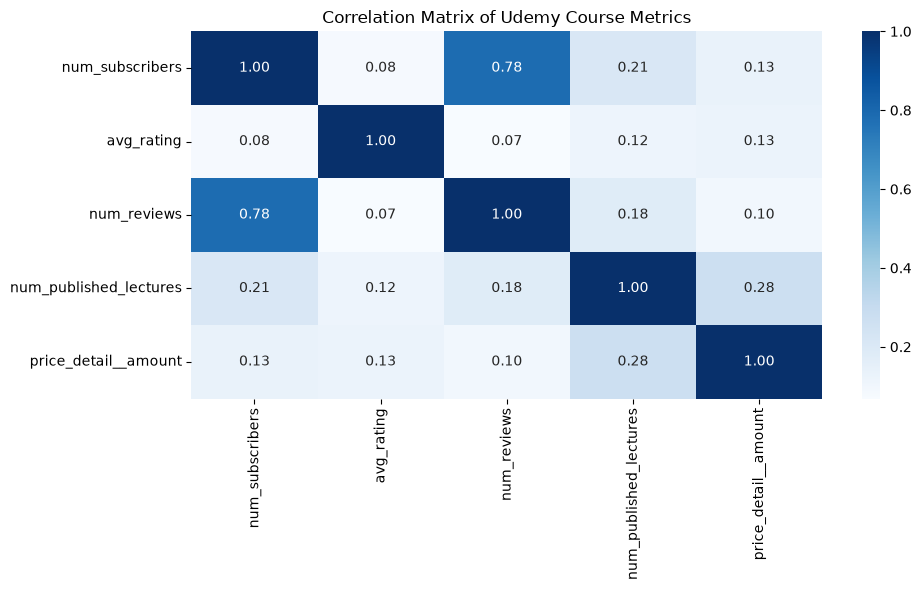

In [3]:
plt.figure(figsize=(10, 6))
sns.heatmap(
    df[
        [
            "num_subscribers",
            "avg_rating",
            "num_reviews",
            "num_published_lectures",
            "price_detail__amount",
        ]
    ].corr(),
    annot=True,
    cmap="Blues",
    fmt=".2f",
)
plt.title("Correlation Matrix of Udemy Course Metrics")
plt.tight_layout()
plt.savefig("correlation_heatmap.png")
plt.show()

**Machine Learning Model for Future Predictions**

In [4]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Define Features and Target
features = [
    "avg_rating",
    "num_published_lectures",
    "num_published_practice_tests",
    "price_detail__amount",
    "discount_pct",
    "course_age_days",
    "is_paid",
]
X = df[features].dropna()
y = df.loc[X.index, "log_subscribers"]

# Train/Test Split
X_train, X_test, y_type_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Initialize and Train Model
model = GradientBoostingRegressor(
    n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42
)
model.fit(X_train, y_type_train)

# Evaluation
y_pred = model.predict(X_test)
print(f"R2 Score: {r2_score(y_test, y_pred):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.3f}")

R2 Score: 0.471
RMSE: 1.717


**Graphical Presentation & Model Interpretability**

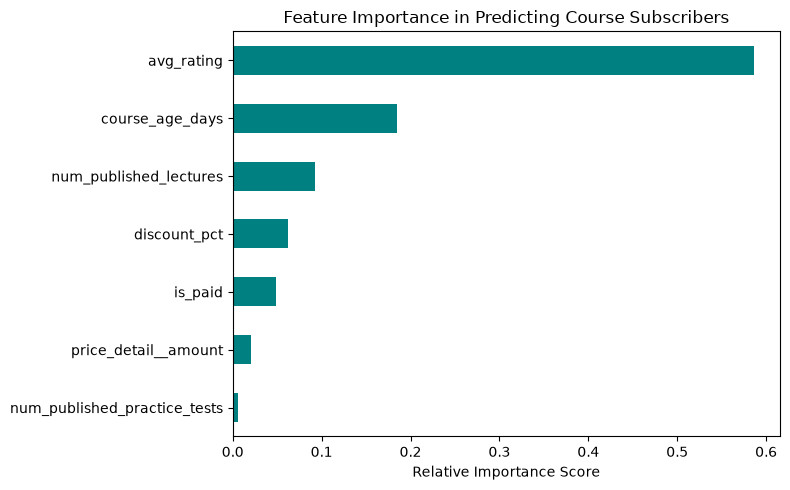

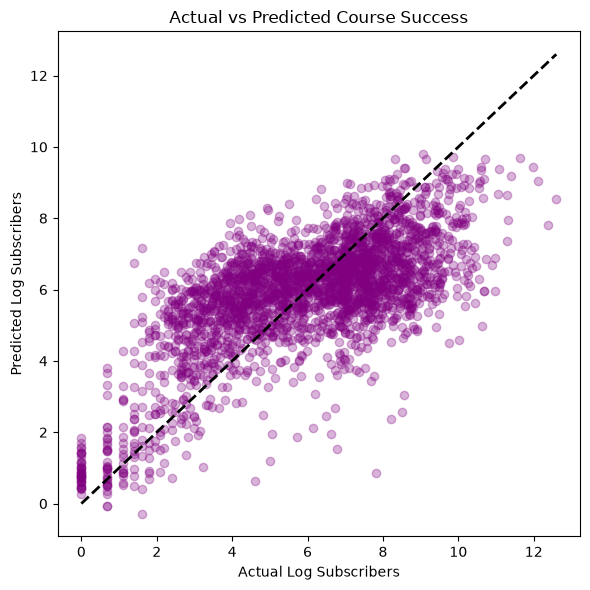

In [5]:
# 1. Feature Importance Plot
plt.figure(figsize=(8, 5))
importances = pd.Series(model.feature_importances_, index=features).sort_values(
    ascending=True
)
importances.plot(kind="barh", color="teal")
plt.title("Feature Importance in Predicting Course Subscribers")
plt.xlabel("Relative Importance Score")
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()

# 2. Actual vs Predicted Plot
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color="purple")
plt.plot(
    [y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--", lw=2
)
plt.xlabel("Actual Log Subscribers")
plt.ylabel("Predicted Log Subscribers")
plt.title("Actual vs Predicted Course Success")
plt.tight_layout()
plt.savefig("actual_vs_predicted.png")
plt.show()